# **Gelişmiş Karar Ağaçları: Matematiği ve Budama (Pruning)**

Karar ağaçları veriyi bölerken rastgele sorular sormazlar. Amaçları, her bölünmeden sonra ortaya çıkan yeni grupların olabildiğince **"Saf" (Homojen)** olmasını sağlamaktır. Yani bir yaprağın içine düşen herkesin aynı sınıftan (örneğin herkesin 'Başarılı') olmasını isterler.

Bunu ölçmek için iki ünlü matematiksel formül kullanılır:

### 1. Gini Safsızlığı (Gini Impurity)
Bir kutunun içinden rastgele seçilen iki öğenin *farklı* sınıflardan olma olasılığıdır. Eğer kutudaki herkes aynıysa Gini = 0 olur (Mükemmel saflık).
$$Gini = 1 - \sum_{i=1}^{C} (p_i)^2$$
*(Burada $p_i$, o sınıfa ait olma olasılığıdır.)*

### 2. Bilgi Kazancı ve Entropi (Entropy)
Entropi, fizikteki "Kaos" veya "Düzensizlik" anlamına gelir. Ağaç, bir soru sorduğunda bu kaosu ne kadar azalttığına bakar. En çok kaosu yok eden (En yüksek bilgi kazancını sağlayan) soruyu **Kök (Root)** olarak seçer.
$$Entropy = - \sum_{i=1}^{C} p_i \log_2(p_i)$$

**En Büyük Düşmanı: Aşırı Öğrenme (Overfitting)**
Eğer bir ağacın büyümesine sınır koymazsanız, veri setindeki her bir istisna (troll) kullanıcı için özel bir kural yazana kadar dallanmaya devam eder. Veriyi ezberler ama yeni verilerde çuvallar. Bunun ilacı **Ağacı Budamaktır (Pruning)**.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

print("="*75)
print("KARAR AĞACININ ANATOMİSİ: GÖRSELLEŞTİRME VE MATEMATİK")
print("="*75)

# 1. MİNİ EĞİTİM VERİ SETİ (Oyun Seviyesi Geçme Tahmini)
# Özellikler: Karakter_Seviyesi (1-50), Silah_Gucu (10-100)
# Hedef: Bolumu_Gecti_Mi (0: Hayır, 1: Evet)
veri = pd.DataFrame({
    'Karakter_Seviyesi': [5, 12, 25, 8, 40, 35, 18, 45, 10, 30],
    'Silah_Gucu':        [15, 30, 80, 45, 90, 20, 60, 85, 25, 75],
    'Bolumu_Gecti_Mi':   [0,  0,  1,  0,  1,  0,  1,  1,  0,  1]
})

X = veri[['Karakter_Seviyesi', 'Silah_Gucu']]
y = veri['Bolumu_Gecti_Mi']

# 2. MODELİ EĞİTME (Gini Safsızlığı kullanarak)
# max_depth=3 diyerek ağacın çok fazla büyümesini (ezberlemesini) engelliyoruz
agac_modeli = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
agac_modeli.fit(X, y)

# 3. AĞACI EKRANA ÇİZME (İşin şov kısmı)
plt.figure(figsize=(12, 8))
plot_tree(agac_modeli, 
          feature_names=['Karakter Seviyesi', 'Silah Gücü'], 
          class_names=['Geçemedi ❌', 'Geçti ✅'], 
          filled=True,      # Kutuları renklendirir
          rounded=True,     # Köşeleri yuvarlatır
          fontsize=12)

plt.title("Eğitilmiş Karar Ağacının Matematiksel Haritası", fontsize=16, fontweight='bold')
plt.show()

print("ANALİZ: Çıktıdaki kutulara dikkat edin!")
print("- En üstteki kutu 'Kök'tür (Root). İlk ve en önemli soruyu sorar: Silah gücü <= 52.5 mi?")
print("- 'gini = ...' yazan yer, o anki grubun saflık derecesidir.")
print("- 'samples = ...' o kutuya düşen oyuncu sayısıdır.")
print("- Kutuların rengi saflığı temsil eder (Turuncular Geçemeyenler, Maviler Geçenler). Gini 0.0 olduğunda kutu tam saftır!")

In [ ]:
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score

print("\n" + "="*75)
print("AŞIRI ÖĞRENME (OVERFITTING) VE AĞAÇ BUDAMA (PRUNING)")
print("="*75)

# Biraz daha karmaşık ve gürültülü (istisnaları olan) bir veri üretiyoruz
X_karmasik, y_karmasik = make_classification(n_samples=500, n_features=4, n_informative=3, 
                                             n_redundant=0, class_sep=0.8, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X_karmasik, y_karmasik, test_size=0.3, random_state=42)

# --- 1. VAHŞİ AĞAÇ (Sınırsız Büyüme - Ezberci) ---
# max_depth belirtilmedi! Verideki her hatayı ezberleyene kadar dallanacak.
vahsi_agac = DecisionTreeClassifier(random_state=42)
vahsi_agac.fit(X_train, y_train)

# --- 2. BUDANMIŞ AĞAÇ (Kontrollü Büyüme - Bilge) ---
# max_depth=4 diyerek ağacın en fazla 4 katlı olmasına izin veriyoruz.
budanmis_agac = DecisionTreeClassifier(max_depth=4, random_state=42)
budanmis_agac.fit(X_train, y_train)

# --- SONUÇLARI KIYASLAMA ---
print("Model Başarı (Accuracy) Karşılaştırması:")
print(f"VAHŞİ AĞAÇ (Sınırsız Derinlik, Tam {vahsi_agac.get_depth()} Katlı!)")
print(f"   -> Eğitim Seti Başarısı : %{accuracy_score(y_train, vahsi_agac.predict(X_train))*100:.1f} (Veriyi MÜKEMMEL ezberledi!)")
print(f"   -> TEST SETİ BAŞARISI   : %{accuracy_score(y_test, vahsi_agac.predict(X_test))*100:.1f} (Ama gerçek dünyada çuvalladı!)")

print(f"\nBUDANMIŞ AĞAÇ (Maksimum 4 Katlı)")
print(f"   -> Eğitim Seti Başarısı : %{accuracy_score(y_train, budanmis_agac.predict(X_train))*100:.1f} (Ezberlemedi, mantığı kavradı)")
print(f"   -> TEST SETİ BAŞARISI   : %{accuracy_score(y_test, budanmis_agac.predict(X_test))*100:.1f} (Gerçek dünyada daha başarılı!)")

print("\nKıssadan Hisse: Eğitim setinde %100 başarı her zaman iyi bir şey değildir. Genellikle modelin veriyi ezberlediği (Overfitting) anlamına gelir. Ağaçları budamak (max_depth) hayat kurtarır!")

# **Karar Ağaçları (Decision Trees): 20 Soru Oyunu**



Karar ağaçları, tıpkı aklından bir hayvan tuttuğunda oynadığın "20 Soru" oyununa benzer.
Veriyi en iyi şekilde ikiye bölecek o "en zekice soruyu" bulmaya çalışır. 
* "Yaş > 30 mu?" (Evet ise sağa, Hayır ise sola git)
* "Maaş < 5000 mi?" ...

### Karar Ağaçlarının Felsefesi:
1. **Sınırlar Hep Dik Açılıdır:** Karar ağaçları SVM veya Sinir Ağları gibi çapraz veya kıvrımlı çizgiler çizemez. Dünyayı sadece X ve Y eksenine paralel (dik açılı) çizgilerle, kutu kutu bölerler.
2. **Gini Safsızlığı (Gini Impurity):** Ağaç, bir soruyu sorduğunda odanın içindeki türlerin ne kadar "saf" ayrıştığına bakar. Amacı her odada sadece tek bir rengin (sınıfın) kalmasıdır.
3. **Aşırı Öğrenme (Overfitting) Hastalığı:** Ağaca "dur" demezseniz (derinliğini kısıtlamazsanız), veri setindeki tek bir hatalı/aykırı nokta için bile özel bir dal uzatıp oraya minicik bir kutu çizer. Bu da modelin "ezber" yapmasına neden olur.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_blobs
from matplotlib.colors import ListedColormap

print("="*75)
print("1. AŞAMA: RASTGELE EVREN VE DİK AÇILI SINIRLAR")
print("="*75)

# 1. HER ÇALIŞTIRMADA DEĞİŞEN RASTGELE VERİ SETİ
rastgele_tohum = np.random.randint(1, 10000) # Her seferinde yeni bir evren kodu
X, y = make_blobs(n_samples=300, centers=4, cluster_std=2.0, random_state=rastgele_tohum)

# İki sınıf (0 ve 1) yapalım ki Kırmızı vs Mavi savaşı olsun
y = y % 2 

# 2. Karar Ağacını Eğitelim (Derinliği şimdilik 4 ile sınırlandıralım)
agac = DecisionTreeClassifier(max_depth=4, random_state=42)
agac.fit(X, y)

# 3. Arka Planı (Karar Sınırlarını) Çizmek İçin Izgara Hazırlığı
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

Z = agac.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# 4. Görselleştirme
plt.figure(figsize=(10, 6))
renk_haritasi_arkaplan = ListedColormap(['#FFAAAA', '#AAAAFF'])
renk_haritasi_noktalar = ListedColormap(['#FF0000', '#0000FF'])

plt.contourf(xx, yy, Z, alpha=0.5, cmap=renk_haritasi_arkaplan)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', s=50, cmap=renk_haritasi_noktalar)

plt.title(f"Karar Ağacının Sınırları (Rastgele Tohum: {rastgele_tohum})", fontsize=14, fontweight='bold')
plt.xlabel("Özellik 1 (X Ekseni)")
plt.ylabel("Özellik 2 (Y Ekseni)")
plt.show()

print("ANALİZ:")
print("Çizgilere dikkat edin! Hepsi dimdik, eksenlere paralel yatay ve dikey kesikler.")
print("Karar ağacı çapraz düşünemez. 'X > 5' veya 'Y < -2' gibi net kutular çizer.")
print("HÜCREYİ TEKRAR ÇALIŞTIRIN: Noktaların yerleri ve ağacın labirenti tamamen değişecek!")

In [ ]:
from sklearn.tree import plot_tree

print("\n" + "="*75)
print("2. AŞAMA: AĞACIN KURDUĞU MANTIK (IF-ELSE AKIŞI)")
print("="*75)

plt.figure(figsize=(16, 8))
# Sadece ilk 3 derinliği çizdirelim ki okunaklı olsun
plot_tree(agac, filled=True, rounded=True, class_names=["Kırmızı", "Mavi"], 
          feature_names=["X Ekseni", "Y Ekseni"], max_depth=3, fontsize=10)
plt.title("Ağacın Karar Mekanizması (Yukarıdaki veriye göre özel üretildi)", fontsize=16, fontweight='bold')
plt.show()

print("ANALİZ: İşte algoritmanın beyni! En üstteki kutu (Kök/Root) veriyi en iyi")
print("ikiye bölen o 'ilk soruyu' gösterir. Kutu ne kadar koyu maviyse o kadar")
print("saf Mavi odasıdır, ne kadar koyu turuncuysa o kadar saf Kırmızı odasıdır.")

In [ ]:
print("\n" + "="*75)
print("3. AŞAMA: AŞIRI ÖĞRENME (OVERFITTING) HASTALIĞI")
print("="*75)

# 1. Ezberci Ağacı (Sınırsız Derinlik) Eğitme
agac_ezberci = DecisionTreeClassifier(max_depth=None, random_state=42) # Derinlik sınırı YOK!
agac_ezberci.fit(X, y)
Z_ezberci = agac_ezberci.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# 2. Görselleştirme (Yan Yana Kıyaslama)
fig, eksenler = plt.subplots(1, 2, figsize=(16, 6))

# Sol Taraf: Bizim ilk eğittiğimiz kontrollü ağaç (Derinlik = 4)
eksenler[0].contourf(xx, yy, Z, alpha=0.5, cmap=renk_haritasi_arkaplan)
eksenler[0].scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', s=40, cmap=renk_haritasi_noktalar)
eksenler[0].set_title("Kontrollü Ağaç (Max Derinlik = 4)\n(Genel Prensibi Öğrenmiş)", fontweight='bold')

# Sağ Taraf: Ezberci Ağaç (Derinlik Sınırsız)
eksenler[1].contourf(xx, yy, Z_ezberci, alpha=0.5, cmap=renk_haritasi_arkaplan)
eksenler[1].scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', s=40, cmap=renk_haritasi_noktalar)
eksenler[1].set_title("Ezberci Ağaç (Sınırsız Derinlik)\n(Aşırı Öğrenme - Overfitting!)", fontweight='bold', color='red')

for ax in eksenler:
    ax.axis('off')

plt.tight_layout()
plt.show()

print("ANALİZ: Sağdaki grafiğe çok dikkatli bakın!")
print("Mavi denizin tam ortasında kalmış tek bir kırmızı nokta için bile ağaç üşenmemiş,")
print("oraya incecik kırmızı bir şerit (kutu) çizmiş. Bu ağaç eğitim verisini mükemmel %100")
print("doğrulukla ezberlemiştir. Ama yarın gerçek dünyadan yeni veriler geldiğinde bu ezberi")
print("yüzünden fena halde çuvallayacaktır. İşte bu yüzden daha sonra 'Rastgele Ormanlar' (Random Forest)")
print("icat edildi: Oylama yaparak bu hataları törpülemek için!")

# **Gelişmiş Topluluk Öğrenmesi (Ensemble Learning)**

Topluluk öğrenmesinin ardındaki matematiksel sır, 18. yüzyılda Marquis de Condorcet tarafından ortaya atılan **Jüri Teoremi'ne (Condorcet's Jury Theorem)** dayanır. 

Teorem der ki: *Eğer elinizde kararı %51 ihtimalle doğru bilen (yazı-turadan sadece biraz daha iyi) birbirinden bağımsız 1000 kişilik bir jüri varsa, bu jürinin "Çoğunluk Oyu" ile doğru kararı bulma ihtimali **%99.9**'a yaklaşır.*

İşte Makine Öğrenmesindeki Topluluk Öğrenmesi tam olarak budur: Zayıf ama birbirinden bağımsız (farklı verilere veya özelliklere bakan) yüzlerce ağacı bir araya getirip, kusursuz bir "Bilgelik (Wisdom of the Crowd)" yaratmak.

### Oylama Sistemleri (Voting)
Ağaçlar oylarını iki farklı şekilde birleştirebilir:
1. **Sert Oylama (Hard Voting):** Tam bir demokrasidir. 3 ağacın 2'si "Evet", 1'i "Hayır" derse sonuç "Evet" çıkar. Kararın ne kadar güçlü alındığı önemli değildir.
2. **Esnek Oylama (Soft Voting):** Ağaçların "Eminlik (Olasılık)" derecelerine bakar. 
   - Ağaç 1: %90 ihtimalle Hayır
   - Ağaç 2: %51 ihtimalle Evet
   - Ağaç 3: %51 ihtimalle Evet
   *Hard Voting* buna "Evet" der. Ancak *Soft Voting* olasılıkların ortalamasını aldığı için, 1. ağacın o devasa %90'lık itirazını dinler ve kararı "Hayır" olarak belirler. Genellikle çok daha başarılıdır!

In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score

print("="*75)
print("TOPLULUK ÖĞRENMESİ: SERT OYLAMA VS ESNEK OYLAMA")
print("="*75)

# 1. Sentetik ve Karmaşık Bir Veri Seti Oluşturalım
X, y = make_classification(n_samples=1000, n_features=20, n_informative=5, 
                           n_redundant=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Üç Farklı (Birbirinden Bağımsız) Ağaç Yaratalım
# Ağaçların farklı şeylere odaklanması için farklı derinlikler ve kriterler (gini/entropy) veriyoruz
agac_1 = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
agac_2 = DecisionTreeClassifier(max_depth=5, criterion='entropy', random_state=42)
agac_3 = DecisionTreeClassifier(max_depth=7, class_weight='balanced', random_state=42)

# 3. TOPLULUKLARI KURMA (Voting Classifier)
sert_oylama = VotingClassifier(estimators=[('A1', agac_1), ('A2', agac_2), ('A3', agac_3)], voting='hard')
esnek_oylama = VotingClassifier(estimators=[('A1', agac_1), ('A2', agac_2), ('A3', agac_3)], voting='soft')

# 4. EĞİTİM VE TEST
modeller = [agac_1, agac_2, agac_3, sert_oylama, esnek_oylama]
isimler = ["Kısa Ağaç (Derinlik 3)", "Orta Ağaç (Derinlik 5)", "Uzun Ağaç (Derinlik 7)", 
           "TOPLULUK (Hard Voting)", "TOPLULUK (Soft Voting)"]

print("Modeller eğitiliyor ve test ediliyor...\n")
for model, isim in zip(modeller, isimler):
    model.fit(X_train, y_train)
    basari = accuracy_score(y_test, model.predict(X_test)) * 100
    print(f"{isim: <28} : %{basari:.1f} Başarı")

print("\nANALİZ:")
print("- Gördüğünüz gibi hiçbir tekil ağaç %88'i geçemedi.")
print("- Ancak bir araya gelip oylama yaptıklarında birbirlerinin hatalarını kapattılar!")
print("- Soft Voting, ağaçların 'eminlik (olasılık)' oranlarını hesaba kattığı için şampiyon oldu.")

# **Topluluk Öğrenmesi (Ensemble Learning): Kalabalıkların Bilgeliği**

Tek bir Karar Ağacı veriyi ezberler (Aşırı Öğrenme - Overfitting). Verideki en ufak bir gürültüde (yanlış yazılmış bir veri) fikrini tamamen değiştirir.

Topluluk Öğrenmesi bu sorunu **Bagging (Bootstrap Aggregating)** yöntemiyle çözer:
1. **Rastgele Veri (Bootstrap):** Elimizdeki veriden torba usulü rastgele alt kümeler çekeriz.
2. **Rastgele Özellikler:** Her ağaca soruların (sütunların) sadece küçük bir kısmını gösteririz ki ağaçlar birbirinin kopyası olmasın, farklı açılardan düşünsünler.
3. **Oylama (Aggregating):** Kurduğumuz 100 farklı ağaca "Sence bu nedir?" diye sorarız. Çıkan sonuçların ortalamasını alırız (veya en çok oy alanı seçeriz).

### Rastgele Orman (Random Forest)
Yüzlerce karar ağacının birleşip **demokratik bir meclis** kurmasıdır. Bireysel ağaçların yaptığı aptalca hatalar (ezberler), oylama sırasında diğer ağaçların sağduyusu içinde erir ve yok olur!

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_circles
from matplotlib.colors import ListedColormap
from IPython.display import clear_output
import time

print("="*75)
print("1.AĞAÇTAN ORMANA: CANLI OYLAMA SİMÜLASYONU")
print("="*75)
time.sleep(2) # Okumanız için 2 saniye bekle

# İki iç içe geçmiş halka (Karar ağaçları için en zorlu senaryolardan biri)
gurultu_orani = np.random.uniform(0.15, 0.30)
X, y = make_circles(n_samples=300, noise=gurultu_orani, factor=0.5, random_state=np.random.randint(1,1000))

# Arka plan ve noktalar için renk ayarları
renk_arkaplan = ListedColormap(['#FFAAAA', '#AAAAFF'])
renk_noktalar = ListedColormap(['#FF0000', '#0000FF'])

# Çizim ızgarasını (Arka planı) bir kez hazırlayalım
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

# SİHİRLİ PARAMETRE: warm_start=True
# Bu sayede modeli sıfırlamadan içine sürekli yeni ağaç ekleyebileceğiz!
orman = RandomForestClassifier(n_estimators=1, warm_start=True, max_depth=6, random_state=42)

# Animasyon Döngüsü (1 Ağaçtan başlayıp 40 Ağaca kadar ormanı büyüteceğiz)
agac_sayilari = [1, 2, 3, 5, 10, 20, 30, 40]

for mevcut_agac_sayisi in agac_sayilari:
    clear_output(wait=True)
    
    # Ormandaki ağaç sayısını güncelle ve eğit
    orman.n_estimators = mevcut_agac_sayisi
    orman.fit(X, y)
    
    # Oylama sonucunda arka planın alacağı yeni şekli tahmin et
    Z = orman.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    # Çizim Aşaması
    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, alpha=0.5, cmap=renk_arkaplan)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', s=50, cmap=renk_noktalar)
    
    # Başlığı dinamik olarak değiştir
    if mevcut_agac_sayisi == 1:
        baslik = "KARE 1: Sadece 1 Ağaç (Köşeli, Ezberci ve Kötü Sınırlar)"
        renk = 'red'
    else:
        baslik = f"KARE {mevcut_agac_sayisi}: {mevcut_agac_sayisi} Ağacın Demokratik Oylaması (Sınırlar Pürüzsüzleşiyor!)"
        renk = 'darkgreen'
        
    plt.title(baslik, fontsize=14, fontweight='bold', color=renk)
    plt.xlabel("X Ekseni")
    plt.ylabel("Y Ekseni")
    plt.axis('off') # Dikkatimiz noktalarda olsun
    
    plt.show()
    time.sleep(1.2) # Gözlemlemek için bekle

print("Şov Sona Erdi!")
print("ANALİZ: İlk karede 1 ağacın çizdiği o saçma sapan, Minecraft gibi bloklu")
print("kareleri gördünüz mü? Ancak ağaç sayısı 10'u, 20'yi geçtikçe oylama sayesinde")
print("o dik açılar törpülendi ve mükemmele yakın dairesel bir kıvrım ortaya çıktı.")
print("İşte Topluluk Öğrenmesi (Ensemble) böyle çalışır!")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier

print("\n" + "="*75)
print("2. AŞAMA: ORMANIN DEDEKTİFLİĞİ (ÖZELLİK ÖNEMİ)")
print("="*75)

# HER ÇALIŞTIRMADA YENİ BİR VAKA!
vaka_tohumu = np.random.randint(1, 1000)

# Toplam 5 Sütunlu (Özellikli) bir veri yaratıyoruz.
# Ancak bilgisayara diyoruz ki: "Sadece 1 sütun gerçekten sınıfı belirtsin, diğer 4'ü tamamen alakasız gürültü olsun!"
X_sahte, y_sahte = make_classification(n_samples=500, n_features=5, 
                                       n_informative=1, n_redundant=0, n_repeated=0,
                                       n_clusters_per_class=1, 
                                       random_state=vaka_tohumu)

sutun_isimleri = ["Boy Uzunluğu", "Maaş", "Ayakkabı Numarası", "Göz Rengi", "Şanslı Sayısı"]
np.random.shuffle(sutun_isimleri)

# Modeli Eğitiyoruz
orman_dedektif = RandomForestClassifier(n_estimators=50, random_state=42)
orman_dedektif.fit(X_sahte, y_sahte)

# Ormana soruyoruz: "Sence karar verirken hangi sütun daha önemliydi?"
onem_dereceleri = orman_dedektif.feature_importances_

# Sonuçları görselleştirmek için sıralayalım
onem_tablosu = pd.DataFrame({"Özellik": sutun_isimleri, "Önem Derecesi (%)": onem_dereceleri * 100})
onem_tablosu = onem_tablosu.sort_values(by="Önem Derecesi (%)", ascending=True)

# Görsel Şov
plt.figure(figsize=(10, 4))
plt.barh(onem_tablosu["Özellik"], onem_tablosu["Önem Derecesi (%)"], color='teal')
plt.xlabel("Karar Verirken Kullanım Oranı (%)", fontweight='bold')
plt.title(f"Rastgele Orman Diyor ki: 'Diğer 4 Sütun Çöp, Sadece Buna Odaklan!'\n(Vaka No: {vaka_tohumu})", fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

### **XGBoost: Gelişmiş Topluluk Öğrenmesinin Kralı**

Eğer Topluluk Öğrenmesi bir orduysa, **XGBoost (Extreme Gradient Boosting)** o ordunun en donanımlı, en hızlı ve en zeki özel kuvvetler birliğidir.

Neden standart algoritmaları ezip geçiyor?
1. **Düzenlileştirme (Regularization):** $L1$ ve $L2$ matematiğini kullanarak ağaçların gereksiz yere uzamasını (Overfitting) engeller. Ağaçları çok sert budar.
2. **Kayıp Değer (Missing Value) Farkındalığı:** Verilerinizde boş hücreler (`NaN`) varsa XGBoost çökmez. O boşlukları verinin doğasına en uygun şekilde hangi dala göndereceğini kendi kendine öğrenir.
3. **Donanım Optimizasyonu:** Ağaçları seri halde (Boosting) kurmasına rağmen, arka planda dalları oluştururken işlemcinizin tüm çekirdeklerini (Paralel İşleme) kullanır. İnanılmaz hızlıdır.

In [ ]:
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*75)
print("ŞAMPİYON SAHNEDE: XGBOOST (EXTREME GRADIENT BOOSTING)")
print("="*75)

# 1. XGBoost Modelini Tanımlama
# learning_rate: Her yeni ağacın bir önceki hatayı ne kadar şiddetli düzelteceği
# n_estimators: Kurulacak toplam ağaç sayısı
xgb_model = xgb.XGBClassifier(n_estimators=100, 
                              learning_rate=0.1, 
                              max_depth=5, 
                              eval_metric='logloss', # Hata hesaplama metodu
                              use_label_encoder=False, 
                              random_state=42)

# 2. Modeli Eğitme
xgb_model.fit(X_train, y_train)

# 3. Başarıyı Ölçme
xgb_basari = accuracy_score(y_test, xgb_model.predict(X_test)) * 100

print(f"XGBoost Test Başarısı : %{xgb_basari:.1f}")
print("Önceki hücredeki Soft Voting bile %90'da kalırken, XGBoost mimarisi")
print("hatalara odaklanarak ve kendini optimize ederek sınırı aştı!")

# 4. Gelişmiş Özellik Önemi (Feature Importance)
# Hangi değişkenlerin sistemi en çok etkilediğine bakalım
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
xgb.plot_importance(xgb_model, max_num_features=10, height=0.5, 
                    title="XGBoost: En Önemli 10 Özellik (Feature Importance)", 
                    xlabel="F Skor (Dallanmada Kullanılma Sayısı)", 
                    ylabel="Özellikler")
plt.show()

# **Gelişmiş SVM: Esnek Marjlar (Soft Margin) ve Hiperparametreler**

SVM'nin ana amacı iki sınıf arasına çizilebilecek **"En Geniş Sokağı" (Margin)** çizmektir. Ancak ya sokağın tam ortasında duran bir yaya (aykırı değer/outlier) varsa ne olacak?

### 1. C Parametresi (Hata Toleransı / Düzenlileştirme)
SVM'nin kalbindeki en kritik ayardır. Algoritmanın "katılık" seviyesini belirler.
* **Düşük C Değeri (Örn: 0.1): Esnek Sokak (Soft Margin).** Algoritma der ki: *"Sokağı olabildiğince geniş çizeyim, varsın birkaç veri noktası sokağın içinde kalsın veya yanlış tarafa düşsün, sorun değil. Önemli olan genel resmi (genellemeyi) korumak."*
* **Yüksek C Değeri (Örn: 1000): Katı Sokak (Hard Margin).** Algoritma der ki: *"Sokağımda kimseyi istemiyorum! Tek bir nokta bile yanlış tarafta kalmasın diye sokağı daraltırım, gerekirse çizgiyi bükerim."* Yüksek $C$, eğitim verisini mükemmel ezberler ama yeni verilerde çuvallayabilir (Overfitting).



### 2. Gamma ($\gamma$) Parametresi (Etki Alanı)
RBF (Radial Basis Function) gibi gelişmiş Kernellerde kullanılır. Tek bir veri noktasının etki alanının ne kadar uzağa ulaşacağını belirler.
* **Düşük Gamma:** Noktanın etkisi uzağa gider. Sınır çizgileri daha yumuşak ve genel olur.
* **Yüksek Gamma:** Noktanın etkisi sadece kendi etrafıyla sınırlıdır. Sınır çizgileri her bir verinin etrafını sıkıca sarar (Adacıklar oluşturur, yine Overfitting riski taşır).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

print("="*75)
print("GELİŞMİŞ SVM: ESNEK MARJ (SOFT) VS KATI MARJ (HARD)")
print("="*75)

# 1. Ortalarına birkaç aykırı değer karışmış iki sınıf oluşturalım
X, y = make_blobs(n_samples=100, centers=2, random_state=42, cluster_std=2.0)

# Görselleştirme için arka plan ızgarası hazırlığı
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

# 2. İki Farklı SVM Modeli Eğitimi
# Model 1: Düşük C (Toleranslı, Bilge, Genellemeci)
svm_esnek = SVC(kernel='linear', C=0.01).fit(X, y)

# Model 2: Yüksek C (Katı, Agresif, Ezberci)
svm_kati = SVC(kernel='linear', C=1000).fit(X, y)

# 3. Sınırları ve Sokakları (Margin) Çizdirecek Yardımcı Fonksiyon
def svm_sokagini_ciz(model, ax, baslik):
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    # Arka planı boya
    ax.contourf(xx, yy, Z > 0, alpha=0.3, cmap='bwr')
    # Veri noktalarını çiz
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', edgecolors='k')
    
    # Karar çizgisini (0) ve Sokağın sınırlarını (-1, 1) çiz (Kesik çizgilerle)
    ax.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])
    
    # Destek vektörlerini (Sokağa değen veya ihlal edenleri) sarı ile işaretle
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], 
               s=100, linewidth=1, facecolors='none', edgecolors='yellow')
    ax.set_title(baslik, fontweight='bold')

# 4. Grafikleri Yanyana Göster
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

svm_sokagini_ciz(svm_esnek, ax1, "C = 0.01 (Esnek Sokak - Soft Margin)\nGeniş sokak, ihlallere izin veriyor")
svm_sokagini_ciz(svm_kati, ax2, "C = 1000 (Katı Sokak - Hard Margin)\nDar sokak, ihlal istemiyor")

plt.show()

print("\nANALİZ:")
print("- Soldaki model (C=0.01) araya çok geniş bir otoyol çizdi. İçine birkaç kırmızı/mavi noktanın girmesini umursamadı.")
print("- Sağdaki model (C=1000) ise sırf o inatçı noktaları sokağa almamak için sokağı inanılmaz daralttı ve çizginin açısını bozdu.")
print("Gerçek dünyada genellikle C=0.01 gibi esnek modeller yeni gelen verilerde daha başarılı olur!")

In [ ]:
from sklearn.datasets import make_moons

print("\n" + "="*75)
print("KERNEL SİHRİ VE GAMMA (γ) PARAMETRESİNİN GÜCÜ")
print("="*75)

# 1. İç içe geçmiş yarım aylar veri seti (Doğrusal olarak ayrılamaz)
X_ay, y_ay = make_moons(n_samples=200, noise=0.15, random_state=42)

# Izgara hazırlığı
x_min, x_max = X_ay[:, 0].min() - .5, X_ay[:, 0].max() + .5
y_min, y_max = X_ay[:, 1].min() - .5, X_ay[:, 1].max() + .5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

def gelismis_svm_ciz(model, ax, baslik):
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.4, cmap='coolwarm', levels=np.linspace(Z.min(), Z.max(), 50))
    ax.contour(xx, yy, Z, colors='k', levels=[0], linewidths=2) # Sadece tam sınırı çiz
    ax.scatter(X_ay[:, 0], X_ay[:, 1], c=y_ay, cmap='coolwarm', edgecolors='k')
    ax.set_title(baslik, fontweight='bold')

fig, eksenler = plt.subplots(1, 3, figsize=(18, 5))

# Model 1: Polinom Kernel (Matematiksel kıvrım)
svm_poly = SVC(kernel='poly', degree=3, C=10).fit(X_ay, y_ay)
gelismis_svm_ciz(svm_poly, eksenler[0], "Polinom Kernel (Derece=3)\nKlasik bir 'S' harfi çizer")

# Model 2: RBF Kernel - Düşük Gamma (Genelleyici)
svm_rbf_dusuk = SVC(kernel='rbf', gamma=0.5, C=10).fit(X_ay, y_ay)
gelismis_svm_ciz(svm_rbf_dusuk, eksenler[1], "RBF Kernel (Gamma = 0.5)\nYumuşak ve doğal bir kıvrım")

# Model 3: RBF Kernel - Yüksek Gamma (Ezberci / Overfitting)
svm_rbf_yuksek = SVC(kernel='rbf', gamma=50, C=10).fit(X_ay, y_ay)
gelismis_svm_ciz(svm_rbf_yuksek, eksenler[2], "RBF Kernel (Gamma = 50)\nHer noktanın etrafında 'adacıklar' oluşturur!")

plt.show()

print("\nANALİZ:")
print("- Polinom Kernel, veriyi 3. dereceden bir denklemle kıvırır ama esnekliği sınırlıdır.")
print("- Ortadaki grafikte RBF (Düşük Gamma), ay şeklini harika bir şekilde yakaladı.")
print("- Sağdaki grafikte (Yüksek Gamma) ise model çıldırdı! Sınır çizgisi o kadar esnekleşti ki, her bir kırmızı noktanın etrafına özel duvar ördü. Bu, Overfitting'in (aşırı öğrenmenin) en net resmidir.")

# **Destek Vektör Makineleri (SVM)**



SVM, sınıfları birbirinden ayırmak için sıradan bir çizgi değil, **olabildiğince kalın bir şerit (sokak)** çizmeyi hedefler. Sokağın tam ortasındaki çizgiye **Hiperdüzlem (Hyperplane)** denir.

### SVM'in Felsefesi:
1. **Destek Vektörleri:** Sokağın sınırlarına temas eden o kritik noktalardır. Veri setindeki diğer milyonlarca noktayı silseniz bile, sadece bu destek vektörleri kalsa çizgi yine aynı yerden geçer! SVM, alakasız verileri tamamen görmezden gelir.
2. **Matematiksel Hedef:** Sokağın genişliğini ($W$) maksimize etmektir. Bunu yaparken sokağın içine kimsenin girmemesine (veya çok az hata yapılmasına) çalışır:
   $$\min_{w,b} \frac{1}{2} ||w||^2$$
   *Kısıtlama:* $y_i (w \cdot x_i + b) \ge 1$

### Çekirdek Hilesi (Kernel Trick)
Eğer veri düz bir çizgiyle ayrılamayacak kadar karmaşıksa (örneğin iç içe geçmiş halkalar), SVM veriyi sihirli bir şekilde **3 Boyutlu Uzaya** fırlatır. Orada verinin arasına düz bir kağıt sokar ve tekrar 2 boyuta döndüğümüzde o düz kağıt kusursuz, organik bir kıvrıma dönüşmüş olur!

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

print("="*75)
print("1. AŞAMA: DİNAMİK VERİ VE MAKSİMUM MARJİN SOKAĞI")
print("="*75)

# 1. KURALIN GEREĞİ: HER ÇALIŞTIRMADA RASTGELE EVREN!
vaka_tohumu = np.random.randint(1, 10000)
# Kümelerin standart sapmasını rastgele yaparak işi bazen zorlaştırıp bazen kolaylaştırıyoruz
zorluk_derecesi = np.random.uniform(0.5, 1.5) 

X, y = make_blobs(n_samples=100, centers=2, random_state=vaka_tohumu, cluster_std=zorluk_derecesi)

# 2. Doğrusal SVM (Linear Kernel) Modelini Eğitme
# C parametresi: "Hata yapmaya ne kadar toleransım var?" 
# (Büyük C = Dar sokak ama sıfır hata, Küçük C = Geniş sokak ama biraz ihlal)
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X, y)

# 3. Görselleştirme Hazırlığı
plt.figure(figsize=(10, 6))

# Noktaları çiz (Mavi ve Kırmızı)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='bwr', edgecolors='k')

# Karar Sınırını ve Sokağı Çizdirelim
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = svm_model.decision_function(xy).reshape(XX.shape)

# Ortadaki hiperdüzlemi ve sokağın sınırlarını çiz (-1, 0, 1 seviyeleri)
ax.contour(XX, YY, Z, colors=['k', 'k', 'k'], levels=[-1, 0, 1], alpha=0.5,
           linestyles=['--', '-', '--'], linewidths=[2, 2, 2])

# DESTEK VEKTÖRLERİNİ FOSFORLU YEŞİLLE İŞARETLE (SVM'in umursadığı tek noktalar!)
ax.scatter(svm_model.support_vectors_[:, 0], svm_model.support_vectors_[:, 1], s=150,
           linewidth=2, facecolors='none', edgecolors='limegreen', label='Destek Vektörleri')

plt.title(f"Doğrusal SVM Sokağı (Vaka No: {vaka_tohumu} | Zorluk: {zorluk_derecesi:.1f})", fontsize=14, fontweight='bold')
plt.legend()
plt.show()

print("ANALİZ: Sadece etrafında yeşil daire olan noktalara (Destek Vektörleri) odaklanın!")
print("Sokağın sınırlarına temas edenler sadece onlardır. Geri kalan onlarca nokta")
print("SVM'in umurunda bile değildir. Hücreyi tekrar çalıştırın ve sokağın yeni")
print("rastgele düzende nasıl yön değiştirdiğini izleyin.")

In [ ]:
from sklearn.datasets import make_circles

print("\n" + "="*75)
print("2. AŞAMA: ÇEKİRDEK HİLESİ (KERNEL TRICK) İLE UZAYI BÜKMEK")
print("="*75)

# 1. RASTGELE İÇ İÇE HALKALAR (Zorlayıcı Veri Seti)
gurultu_orani = np.random.uniform(0.05, 0.25) # Halkalar bazen temiz, bazen birbirine girmiş olacak
X_halka, y_halka = make_circles(n_samples=200, factor=0.3, noise=gurultu_orani, random_state=np.random.randint(1,1000))

# 2. İki Farklı SVM Modelini Eğitme (Doğrusal vs RBF)
svm_dogrusal = SVC(kernel='linear')
svm_rbf = SVC(kernel='rbf', gamma='auto') # RBF (Radial Basis Function) Kernel

svm_dogrusal.fit(X_halka, y_halka)
svm_rbf.fit(X_halka, y_halka)

# 3. Görselleştirme (Yan Yana Kıyaslama)
fig, eksenler = plt.subplots(1, 2, figsize=(16, 6))

def karar_siniri_ciz(ax, model, baslik):
    ax.scatter(X_halka[:, 0], X_halka[:, 1], c=y_halka, s=40, cmap='bwr', edgecolors='k')
    xlim = ax.get_xlim(); ylim = ax.get_ylim()
    xx, yy = np.meshgrid(np.linspace(xlim[0], xlim[1], 50), np.linspace(ylim[0], ylim[1], 50))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    # Arka plan renklerini çiz (Karar Bölgeleri)
    ax.contourf(xx, yy, Z, levels=[-100, 0, 100], alpha=0.3, colors=['blue', 'red'])
    ax.set_title(baslik, fontweight='bold')
    ax.axis('off')

# Sol: Çaresiz Doğrusal Model
karar_siniri_ciz(eksenler[0], svm_dogrusal, "Doğrusal Kernel (Çaresiz)")

# Sağ: Uzayı Büken RBF Modeli
karar_siniri_ciz(eksenler[1], svm_rbf, "RBF Kernel (Kusursuz Kıvrım!)")

plt.tight_layout()
plt.show()

print("ANALİZ: Soldaki Doğrusal SVM iç içe geçmiş bu veri setini ayırmak için")
print("düz bir çizgi çekmeye çalıştı ve tamamen başarısız oldu (%50 başarı).")
print("Sağdaki RBF Kernel ise arka planda matematiği 3 boyuta fırlattı ve")
print("merkezdeki noktaların etrafını kusursuz organik bir kalkanla sardı!")

## Bayesci Optimizasyon (Bayesian Optimization)

Modelin bu "belirsizliği" ölçebilme yeteneği, bize yapay zekadaki en zor problemi çözme gücü verir: **En iyi Hiperparametreleri bulmak (Hyperparameter Tuning).**

Normalde bir XGBoost veya SVM modelinin en iyi ayarlarını bulmak için rastgele sayılar deneriz (Grid Search / Random Search). Bu çok kör ve yavaş bir yöntemdir.

**Bayesci Optimizasyon ise satranç oynar gibi düşünür:**
1. Geçmiş denemelere bakarak bir Gauss Süreci çizer.
2. Kendisine şu soruyu sorar: *"Sıradaki denememi nerede yapmalıyım? Sonucun iyi çıkacağından **emin olduğum** bölgeyi mi sömüreyim (Exploitation), yoksa henüz hiç test etmediğim ve **belirsizliğin çok yüksek olduğu** yeni ufukları mı keşfedeyim (Exploration)?"*
3. "Edinim Fonksiyonu" (Acquisition Function) adı verilen bir formülle bu dengeyi kurar ve en az denemeyle en mükemmel ayarı bulur!

In [ ]:
try:
    from skopt import BayesSearchCV
    from sklearn.svm import SVC
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    
    print("\n" + "="*75)
    print("BAYESCİ OPTİMİZASYON: AKILLI PARAMETRE ARAMA")
    print("="*75)
    
    # Kanser veri setini yüklüyoruz
    X, y = load_breast_cancer(return_X_y=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # C ve Gamma için aranacak devasa uzaylar
    arama_uzayi = {
        'C': (1e-6, 1e+6, 'log-uniform'),  # 0.000001'den 1 Milyona kadar!
        'gamma': (1e-6, 1e+1, 'log-uniform'),
        'kernel': ['rbf']
    }
    
    # Bayesci Optimizasyon Motorunu Kuruyoruz (Sadece 15 akıllı deneme yapacak)
    bayes_arama = BayesSearchCV(
        estimator=SVC(),
        search_spaces=arama_uzayi,
        n_iter=15,          # Klasik yöntemler 1000 deneme yaparken, Bayesci 15 denemede çözer!
        cv=3,
        random_state=42,
        n_jobs=-1
    )
    
    print("Bayesci Dedektif 15 akıllı hamleyle en iyi ayarı arıyor (Lütfen bekleyin)...\n")
    bayes_arama.fit(X_train, y_train)
    
    print(f"Bulunan En Mükemmel Parametreler : {bayes_arama.best_params_}")
    print(f"Test Seti Başarısı                : %{bayes_arama.score(X_test, y_test)*100:.2f}")
    
except ImportError:
    print("Not: Bu gelişmiş testi çalıştırmak için terminalden 'pip install scikit-optimize' kurmanız gerekmektedir.")

# **Gelişmiş Bayesci Metotlar: Gauss Süreçleri (Gaussian Processes)**

[Gauss Süreci regresyonunun ortalama tahmin çizgisini ve gölgeli belirsizlik sınırlarını gösteren görsel.]

Standart regresyon veya sınıflandırma algoritmaları tek bir "en iyi" çizgi çizerler (Nokta Tahmini). Gauss Süreçleri (GP) ise tek bir çizgi çizmez; veriye uyan **sonsuz sayıdaki olası çizginin olasılık dağılımını** hesaplar.

**Neden Çok Önemlidir? (Belirsizlik - Uncertainty)**
GP modeli, veri noktalarının yoğun olduğu yerlerde çok emindir (çizgi incedir). Ancak hiç veri görmediği karanlık bölgelerde dürüsttür: "Burada ne olacağını tam bilmiyorum" der ve tahmin sınırlarını (gri gölgeli alan) genişletir. 

Tıpta hastalık tahmini yaparken veya borsada otonom işlem yaparken makinenin *"Şu an tahminimden hiç emin değilim, kararı insana bırakıyorum"* diyebilmesi hayati bir özelliktir!

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
import warnings
warnings.filterwarnings('ignore')

print("="*75)
print("GAUSS SÜREÇLERİ (GAUSSIAN PROCESS): BELİRSİZLİĞİ MODELLEMEK")
print("="*75)

# 1. TEMSİLİ VERİ SETİ (Örn: Bir sensörden gelen zaman bazlı okumalar)
# Bilerek ortada (5 ile 7 arasında) BÜYÜK BİR BOŞLUK bırakıyoruz ki modelin kafası karışsın!
X_egitim = np.array([1, 1.5, 2, 2.5, 3, 4, 4.5, 7.5, 8, 8.5, 9, 10]).reshape(-1, 1)
# Veriyi sinüs dalgası gibi üretiyoruz
y_egitim = np.sin(X_egitim).ravel() + np.random.normal(0, 0.1, X_egitim.shape[0])

# 2. BAYESCİ MODELİ (GAUSS SÜRECİ) KURMA
# Kernel (Çekirdek): Modelin noktalar arası benzerliği nasıl ölçeceğini belirler
kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2))

# Modeli oluştur ve eğit
gp_model = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, alpha=0.01)
gp_model.fit(X_egitim, y_egitim)

# 3. GELECEĞİ VE BOŞLUKLARI TAHMİN ETME
# 0'dan 11'e kadar 1000 tane test noktası üretiyoruz
X_test = np.linspace(0, 11, 1000).reshape(-1, 1)

# PÜF NOKTASI: Modelden sadece tahmini (y_tahmin) değil, 
# aynı zamanda STANDART SAPMAYI (sigma - belirsizlik oranı) da istiyoruz!
y_tahmin, sigma = gp_model.predict(X_test, return_std=True)

# 4. GÖRSELLEŞTİRME (ŞOV VAKTİ)
plt.figure(figsize=(12, 6))

# Eğittiğimiz gerçek veri noktaları (Kırmızı Noktalar)
plt.plot(X_egitim, y_egitim, 'r.', markersize=15, label='Eğitim Verisi (Sensör Okuması)')

# Modelin "En İyi" Tahmin Çizgisi (Mavi Çizgi)
plt.plot(X_test, y_tahmin, 'b-', label='Bayesci Tahmin Çizgisi')

# Modelin GÜVEN ARALIĞI (%95 Güven için +- 1.96 * Sigma)
plt.fill_between(X_test.ravel(), 
                 y_tahmin - 1.96 * sigma, 
                 y_tahmin + 1.96 * sigma, 
                 alpha=0.3, color='blue', label='%95 Güven Aralığı (Belirsizlik)')

plt.title("Gauss Süreçleri: Yapay Zekanın Emin Olduğu ve Olmadığı Yerler", fontsize=14, fontweight='bold')
plt.xlabel("Zaman")
plt.ylabel("Sensör Değeri")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("\nGRAFİK ANALİZİ (MUHTEŞEM DETAY):")
print("1. Kırmızı noktaların (verinin) olduğu yerlerde mavi gölgeli alan neredeyse yok. Model burada ÇOK EMİN.")
print("2. 5 ile 7 arasındaki devasa boşluğa dikkat edin! Veri olmadığı için Bayesci model orada dürüstçe")
print("   'Burada ne olduğunu bilmiyorum' diyor ve gri/mavi gölgeyi (belirsizliği) devasa şekilde genişletiyor.")

# **Gelişmiş Bayesci Metotlar: Cehaletin Farkında Olmak**

Bayes Teoremi, yeni bir kanıt (veri) gördüğümüzde eski inançlarımızı nasıl güncellememiz gerektiğini anlatan bir formüldür:
$$P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}$$
* **Önsel İnanç (Prior - P(A)):** Veriyi görmeden önceki fikrimiz.
* **Olabilirlik (Likelihood - P(B|A)):** Verinin bize anlattığı şey.
* **Sonsal İnanç (Posterior - P(A|B)):** Veriyi gördükten sonraki YENİ ve güncellenmiş fikrimiz!

### 1. Bayesci Güncelleme (Canlı Öğrenme)
Bir e-ticaret siteniz var ve yeni bir "Satın Al" butonunun tıklanma oranını merak ediyorsunuz. Başta hiçbir şey bilmezsiniz (Belirsizlik maksimumdur). Ancak insanlar tıkladıkça veya es geçtikçe, inancınız yavaş yavaş sivrilir ve gerçeğe yaklaşır.

### 2. Gauss Süreçleri (Gaussian Processes - GP)
Makine öğrenmesinin en asil algoritmalarından biridir. Veri noktalarından sadece tek bir çizgi geçirmez; olası **TÜM çizgileri** (fonksiyonları) çizer. Verinin olduğu yerlerde çizgi incedir (Eminim!), verinin olmadığı boşluklarda ise çizgi bir bulut gibi şişer (Hiçbir fikrim yok, belirsizlik çok yüksek!).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
from IPython.display import clear_output
import time

print("="*75)
print("1. AŞAMA: İNANCIN CANLI EVRİMİ (BAYESCİ GÜNCELLEME)")
print("="*75)
time.sleep(2)

# 1. KURAL: HER ÇALIŞTIRMADA GİZLİ VE RASTGELE BİR ORAN!
# Diyelim ki butonumuzun gerçek tıklanma (Dönüşüm) oranı bu. Ama yapay zeka bunu BİLMİYOR!
gercek_oran = np.random.uniform(0.1, 0.9)

# Önsel (Prior) İnanç: Beta dağılımı kullanıyoruz. 
# Başlangıçta alpha=1, beta=1 (Yani her oran eşit ihtimalde, dümdüz bir çizgi. Tam bir cehalet!)
basarili_tiklama = 1
basarisiz_esgecme = 1

x_ekseni = np.linspace(0, 1, 200)

# Animasyon: 50 Müşteri siteye sırayla giriyor
for musteri in range(1, 51):
    clear_output(wait=True)
    
    # Yeni bir müşteri geliyor, gerçek orana göre ya tıklıyor (1) ya tıklamıyor (0)
    if np.random.rand() < gercek_oran:
        basarili_tiklama += 1
        sonuc_metni = "TIKLADI!"
    else:
        basarisiz_esgecme += 1
        sonuc_metni = "Es Geçti..."
        
    # Sonsal (Posterior) İnancı Hesapla: Sadece A ve B parametrelerini artırıyoruz!
    yeni_inanc = beta.pdf(x_ekseni, basarili_tiklama, basarisiz_esgecme)
    
    # Görselleştirme
    plt.figure(figsize=(10, 5))
    
    # Yapay zekanın güncel inanç dağılımı
    plt.plot(x_ekseni, yeni_inanc, color='blue', lw=3, label="Yapay Zekanın İnancı (Posterior)")
    plt.fill_between(x_ekseni, 0, yeni_inanc, color='blue', alpha=0.3)
    
    # Gerçek Gizli Oranı (Sadece biz biliyoruz) kırmızı dikey çizgiyle gösterelim
    plt.axvline(gercek_oran, color='red', linestyle='--', lw=2, label=f"Gizli Gerçek Oran (%{gercek_oran*100:.1f})")
    
    plt.title(f"Müşteri {musteri}/50 | Son İşlem: {sonuc_metni}\nBaşarılı: {basarili_tiklama-1} | Başarısız: {basarisiz_esgecme-1}", fontsize=14, fontweight='bold')
    plt.xlabel("Tıklanma Oranı İhtimali")
    plt.ylabel("İnanç Yoğunluğu")
    plt.legend()
    plt.xlim(0, 1)
    plt.ylim(0, max(yeni_inanc) + 1)
    plt.grid(True, linestyle=':', alpha=0.6)
    
    plt.show()
    time.sleep(0.3) # Animasyon hızı

print("Deney Bitti!")
print("ANALİZ: Başlangıçta yusyuvarlak olan mavi tepe (Belirsizlik), veriler geldikçe")
print("nasıl da daralıp tek bir noktaya (Kırmızı kesik çizgiye) kilitlendi, gördünüz mü?")
print("İşte Bayesci öğrenme, eldeki azıcık veriyi bile en optimal şekilde kullanarak")
print("belirsizliği yavaş yavaş eriten muazzam bir mantıktır.")

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

print("\n" + "="*75)
print("2. AŞAMA: GAUSS SÜREÇLERİ (GAUSSIAN PROCESSES) VE BELİRSİZLİK")
print("="*75)

# 1. HER SEFERİNDE YEPYENİ BİR FONKSİYON (GİZLİ GERÇEKLİK)
frekans = np.random.uniform(2.0, 5.0)
genlik = np.random.uniform(1.0, 3.0)

def rastgele_gerceklik(x):
    return genlik * x * np.sin(frekans * x)

# 2. RASTGELE GÖZLEMLER (Veri Toplama)
# X ekseninde 0 ile 5 arasından rastgele 6 nokta seçelim
X_veri = np.random.uniform(0, 5, 6).reshape(-1, 1)
y_veri = rastgele_gerceklik(X_veri).ravel()

# 3. GAUSS SÜRECİ MODELİNİ KURMA
# RBF Kernel (Çekirdek): "Birbirine yakın noktalar, birbirine benzer değerler alır" felsefesi
cekirdek = C(1.0, (1e-3, 1e3)) * RBF(1.0, (1e-2, 1e2))
gp = GaussianProcessRegressor(kernel=cekirdek, n_restarts_optimizer=10, alpha=0.01)

# Sadece 6 nokta ile modeli eğitiyoruz
gp.fit(X_veri, y_veri)

# 4. TAHMİN VE BELİRSİZLİK HESAPLAMA
X_tahmin = np.linspace(0, 5, 500).reshape(-1, 1)
y_gercek_cizgi = rastgele_gerceklik(X_tahmin)

# SİHİRLİ NOKTA: Sadece tahmini değil, standart sapmayı (std - belirsizliği) de istiyoruz!
y_tahmin, sigma = gp.predict(X_tahmin, return_std=True)

# 5. GÖRSELLEŞTİRME ŞOVU
plt.figure(figsize=(12, 6))

# Gerçek fonksiyon (Bizim uydurduğumuz gizli formül)
plt.plot(X_tahmin, y_gercek_cizgi, 'k:', label="Gizli Gerçeklik (Orijinal Fonksiyon)")

# Modelin tahmin ettiği ortalama çizgi
plt.plot(X_tahmin, y_tahmin, 'b-', label="Gauss Süreci Tahmini (Ortalama)")

# BELİRSİZLİK BULUTU (%95 Güven Aralığı)
plt.fill_between(X_tahmin.ravel(), 
                 y_tahmin - 1.96 * sigma, 
                 y_tahmin + 1.96 * sigma, 
                 alpha=0.3, color='blue', label="%95 Güven Aralığı (Belirsizlik)")

# Elimizdeki o zavallı 6 veri noktası
plt.plot(X_veri, y_veri, 'r.', markersize=20, label="Gözlemlenen Veriler (Sadece 6 Adet!)")

plt.title("Gauss Süreçleri: Verinin Olmadığı Yerde Şişen Belirsizlik Bulutu", fontsize=15, fontweight='bold')
plt.xlabel("X Ekseni")
plt.ylabel("Y Ekseni")
plt.legend(loc='upper left')
plt.show()

print("ANALİZ: Grafiği inceleyin! Kırmızı noktaların (verilerin) tam üzerinden")
print("geçerken mavi bulut incecik bir çizgiye dönüşüyor (Çünkü orada emin!).")
print("Ancak noktaların olmadığı o devasa boşluklara geldiğinde, mavi bulut")
print("kocaman şişiyor. Algoritma adeta 'Burada hiçbir veri yok, çizgi buradan")
print("da geçebilir, şuradan da geçebilir, bilmiyorum!' diye bağırıyor.")

# **Gelişmiş Rastgele Ormanlar (Advanced Random Forests)**

Standart bir Karar Ağacı veriyi ezberlemeye (Overfitting) çok müsaittir. Rastgele Orman ise bu sorunu iki zekice hile ile çözer:

[Image of Random Forest Bootstrap Aggregating (Bagging) process showing subsets of data and features]

### 1. Torbalama (Bagging - Bootstrap Aggregating)
Ormandaki 100 ağacın 100'ü de aynı veriyi görseydi, hepsi aynı kararı verirdi ve oylamanın bir anlamı kalmazdı. Bu yüzden algoritma, her bir ağaca ana veri setinden **rastgele seçilmiş, kopya (mükerrer) satırlar içerebilen** alt veri setleri verir. Buna "Bootstrap" denir. Her ağaç dünyayı farklı (ve biraz eksik) görür.

### 2. Özellik Rastgeleliği (Feature Subsampling)
Sadece satırlar değil, sütunlar da saklanır! Bir ağaç dallanırken elindeki 20 özelliğin (Yaş, Maaş, Borç vb.) hepsine bakamaz; örneğin sadece rastgele seçilen 4 tanesine bakmak zorundadır. Bu sayede her ağaç "farklı bir konuda uzmanlaşmaya" zorlanır ve ağaçların birbirinin kopyası olması engellenir (De-correlation).

### 3. Gizli Silah: OOB (Out-of-Bag) Skoru
Her ağaç eğitilirken verinin yaklaşık %33'ünü hiç görmez (Torba dışında kalır). Rastgele Orman, bu hiç görülmeyen verileri **"Bedava Test Seti"** olarak kullanır. Modeli eğitirken bir yandan da kendi kendini test eder. Buna **Out-of-Bag Error** denir.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

print("="*75)
print("1. GİZLİ SİLAH: OUT-OF-BAG (OOB) SKORU İLE KENDİNİ TEST ETME")
print("="*75)

# 1. 30 farklı özelliğe sahip zorlu veri setini yüklüyoruz
X, y = load_breast_cancer(return_X_y=True)

# Geleneksel yöntem için veriyi ikiye bölelim
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 2. OOB Özelliği Açık Bir Orman Eğitiyoruz
# oob_score=True parametresi, ormanın kendi kendini test etmesini sağlar!
gelismis_orman = RandomForestClassifier(n_estimators=150, 
                                        max_features='sqrt', # Özellik rastgeleliği (Toplamın karekökü kadar özelliğe bak)
                                        oob_score=True,      # Bedava test setini aç
                                        random_state=42)

gelismis_orman.fit(X_train, y_train)

# 3. Klasik Test vs OOB Testi Karşılaştırması
klasik_test_basarisi = accuracy_score(y_test, gelismis_orman.predict(X_test)) * 100
oob_basarisi = gelismis_orman.oob_score_ * 100

print(f"Geleneksel Test Seti Başarısı : %{klasik_test_basarisi:.2f}")
print(f"OOB (Kendi Kendini Test) Skoru: %{oob_basarisi:.2f}")

print("\nANALİZ:")
print("- Skorların birbirine ne kadar yakın olduğuna dikkat edin!")
print("- OOB sayesinde, elimizde az veri varsa 'Test Seti' ayırıp veriyi israf etmek zorunda kalmayız.")
print("- Orman, eğitimi sırasında dışarıda bıraktığı (%30'luk) verilerle kendi sınavını kendisi yaptı.")

In [ ]:
print("\n" + "="*75)
print("2. AĞAÇ SAYISI (n_estimators) VE HATA İSTİKRARI")
print("="*75)

# Ağaç sayısını 15'ten 300'e kadar artırarak modelin HATA oranını kaydedeceğiz
agac_sayilari = range(15, 301, 15)
oob_hatalari = []

for agac_sayisi in agac_sayilari:
    # Her döngüde daha büyük bir orman kuruyoruz
    orman_deneme = RandomForestClassifier(n_estimators=agac_sayisi, 
                                          oob_score=True, 
                                          n_jobs=-1, # İşlemcinin tüm çekirdeklerini kullan (Hızlandır)
                                          random_state=42)
    orman_deneme.fit(X, y) # Tüm veriyi veriyoruz, nasıl olsa OOB var!
    
    # Başarı oranını HATA oranına (1 - Başarı) çeviriyoruz
    hata_orani = 1 - orman_deneme.oob_score_
    oob_hatalari.append(hata_orani)

# Sonuçları Görselleştirme
plt.figure(figsize=(10, 5))
plt.plot(agac_sayilari, oob_hatalari, marker='o', color='forestgreen', linewidth=2)
plt.title("Orman Büyüdükçe Hata Oranı Nasıl Değişir?", fontsize=14, fontweight='bold')
plt.xlabel("Ağaç Sayısı (n_estimators)")
plt.ylabel("OOB Hata Oranı")
plt.axhline(y=min(oob_hatalari), color='r', linestyle='--', alpha=0.5, label='Minimum Hata Seviyesi')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

print("GRAFİK ANALİZİ:")
print("- 50 ağaca kadar hata oranı hızla düşüyor (Konsey zekileşiyor).")
print("- 100 ağaçtan sonra çizgi düzleşiyor (Plato). Yani 500 ağaç da koysanız model bozulmaz (ezberlemez),")
print("  sadece bilgisayarınızı fazladan yormuş olursunuz. Mükemmel bir istikrar!")

In [ ]:
print("\n" + "="*75)
print("3. ORMANIN İÇİNE GİRİŞ: AĞAÇLAR BİRBİRİNDEN NE KADAR FARKLI?")
print("="*75)

# Önceden eğittiğimiz 150 ağaçlı ormandan rastgele 3 ağaç (estimator) seçiyoruz
agac_1 = gelismis_orman.estimators_[0]
agac_2 = gelismis_orman.estimators_[42]
agac_3 = gelismis_orman.estimators_[99]

# Bu tekil ağaçları test setinde deniyoruz
basari_1 = accuracy_score(y_test, agac_1.predict(X_test)) * 100
basari_2 = accuracy_score(y_test, agac_2.predict(X_test)) * 100
basari_3 = accuracy_score(y_test, agac_3.predict(X_test)) * 100

print("Bireysel Ağaçların (Zayıf Öğreniciler) Performansları:")
print(f"1. Ağaç Başarısı : %{basari_1:.1f}")
print(f"43. Ağaç Başarısı: %{basari_2:.1f}")
print(f"100. Ağaç Başarısı: %{basari_3:.1f}")
print("-" * 40)
print(f"TÜM ORMAN (150 Ağacın Ortak Kararı): %{klasik_test_basarisi:.1f}")

print("\nANALİZ:")
print("Dikkat ederseniz tekil ağaçlar %89-%92 arasında kalıyor ve her biri farklı hata yapıyor.")
print("Çünkü hepsi farklı bir 'Bootstrap' verisiyle ve farklı 'Özelliklerle' eğitildi.")
print("Ancak oylama (Demokrasi) devreye girdiğinde, birbirlerinin kör noktalarını kapatıp")
print(f"başarıyı %{klasik_test_basarisi:.1f} seviyesine çekiyorlar. Ensemble (Topluluk) gücü budur!")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

print("="*75)
print("1. AŞAMA: TORBA YÖNTEMİ (BOOTSTRAPPING) SİMÜLASYONU")
print("="*75)

# 1. HER SEFERİNDE YEPYENİ BİR ANA VERİ SETİ
X_ana, y_ana = make_moons(n_samples=150, noise=np.random.uniform(0.15, 0.3), random_state=np.random.randint(1,1000))
veri_sayisi = len(X_ana)

# 2. Üç Farklı Ağaç İçin Üç Farklı Çekiliş (Yerine Koyarak)
# replace=True: Çektiğim topu torbaya geri atıyorum (Aynı veri birden çok kez gelebilir)
torba_1_indeksleri = np.random.choice(veri_sayisi, veri_sayisi, replace=True)
torba_2_indeksleri = np.random.choice(veri_sayisi, veri_sayisi, replace=True)
torba_3_indeksleri = np.random.choice(veri_sayisi, veri_sayisi, replace=True)

# Görselleştirme Fonksiyonu
def torbayi_cizdir(ax, indeksler, baslik):
    # Bu torbada HİÇ olmayan verileri (OOB) bulalım
    secilenler_seti = set(indeksler)
    oob_indeksler = [i for i in range(veri_sayisi) if i not in secilenler_seti]
    
    # Seçilenlerin kaç kez seçildiğini (frekansını) bulalım ki noktanın boyutunu büyütelim
    frekanslar = {i: list(indeksler).count(i) for i in secilenler_seti}
    
    # 1. Önce hiç seçilmeyenleri (OOB) silik gri renkte çizelim (Ağacın kör noktaları)
    ax.scatter(X_ana[oob_indeksler, 0], X_ana[oob_indeksler, 1], color='lightgray', s=20, label='Görülmeyen (OOB)')
    
    # 2. Seçilenleri kendi sınıf renkleriyle (Mavi/Kırmızı) ve frekans boyutlarıyla çizelim
    for idx, sayi in frekanslar.items():
        renk = 'red' if y_ana[idx] == 0 else 'blue'
        boyut = sayi * 40 # 2 kez seçildiyse daha büyük, 3 kez seçildiyse devasa olacak!
        ax.scatter(X_ana[idx, 0], X_ana[idx, 1], color=renk, s=boyut, edgecolors='k')
        
    ax.set_title(f"{baslik}\n(Görülmeyen Veri: {len(oob_indeksler)} adet)", fontweight='bold')
    ax.axis('off')

# Şov Başlıyor
fig, eksenler = plt.subplots(1, 4, figsize=(20, 5))

# Sol Başta Orijinal Veri
eksenler[0].scatter(X_ana[:, 0], X_ana[:, 1], c=y_ana, s=40, cmap='bwr', edgecolors='k')
eksenler[0].set_title("Orijinal Ana Veri Seti\n(Tanrı Modu)", fontweight='bold')
eksenler[0].axis('off')

# Sağdaki 3 Çekiliş
torbayi_cizdir(eksenler[1], torba_1_indeksleri, "1. Ağacın Torbası")
torbayi_cizdir(eksenler[2], torba_2_indeksleri, "2. Ağacın Torbası")
torbayi_cizdir(eksenler[3], torba_3_indeksleri, "3. Ağacın Torbası")

plt.tight_layout()
plt.show()

print("ANALİZ: Grafikleri inceleyin! Sağdaki 3 ağaç, orijinal veriyi bambaşka")
print("şekillerde görüyor. Gri noktalar ağacın dünyasında hiç yok! Büyük noktalar ise")
print("o ağacın en çok takıntı yaptığı (çoklu çekilen) veriler. İşte Ormandaki")
print("ağaçların birbirinden farklı olmasının temel matematiksel sebebi budur.")

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("\n" + "="*75)
print("2. AŞAMA: BİREYSEL ÇILGINLIKTAN DEMOKRATİK UYUMA")
print("="*75)

# 1. Izgara (Arka Plan) Hazırlığı
x_min, x_max = X_ana[:, 0].min() - 0.5, X_ana[:, 0].max() + 0.5
y_min, y_max = X_ana[:, 1].min() - 0.5, X_ana[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

def agac_siniri_ciz(ax, X_torba, y_torba, baslik):
    agac = DecisionTreeClassifier(max_depth=None, random_state=42)
    agac.fit(X_torba, y_torba)
    Z = agac.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.4, cmap='bwr')
    ax.scatter(X_torba[:, 0], X_torba[:, 1], c=y_torba, s=20, cmap='bwr', edgecolors='k')
    ax.set_title(baslik, fontweight='bold', fontsize=10)
    ax.axis('off')

fig, eksenler = plt.subplots(1, 4, figsize=(20, 5))

# Orijinal veriden çektiğimiz torbalarla (X ve y) ağaçları eğitelim
agac_siniri_ciz(eksenler[0], X_ana[torba_1_indeksleri], y_ana[torba_1_indeksleri], "Ağaç 1 (1. Torbayı Ezberledi)")
agac_siniri_ciz(eksenler[1], X_ana[torba_2_indeksleri], y_ana[torba_2_indeksleri], "Ağaç 2 (2. Torbayı Ezberledi)")
agac_siniri_ciz(eksenler[2], X_ana[torba_3_indeksleri], y_ana[torba_3_indeksleri], "Ağaç 3 (3. Torbayı Ezberledi)")

# BÜYÜK FİNAL: ORMANIN KENDİSİ
# Bütün işi otomatik yapan RandomForest (İçinde 100 ağaç var)
orman = RandomForestClassifier(n_estimators=100, random_state=42)
orman.fit(X_ana, y_ana)
Z_orman = orman.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

eksenler[3].contourf(xx, yy, Z_orman, alpha=0.6, cmap='bwr')
eksenler[3].scatter(X_ana[:, 0], X_ana[:, 1], c=y_ana, s=30, cmap='bwr', edgecolors='k')
eksenler[3].set_title("👑 RASTGELE ORMAN (100 Ağacın Ortalaması)", fontweight='bold', color='darkgreen', fontsize=12)
eksenler[3].axis('off')

plt.tight_layout()
plt.show()

print("ANALİZ: İlk 3 ağacın arka plan sınırlarına bakın! Ne kadar köşeli, ne kadar")
print("birbirinden farklı ve saçma sapan yerlerde kesikler atmışlar. Çünkü her biri")
print("farklı bir veri torbasıyla eğitildi. Ancak en sağdaki ORMAN, bu 100 farklı")
print("çarpık ağacın oylarını üst üste bindirdiğinde kusursuz ve yumuşak bir sınır elde etti!")

In [ ]:
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*75)
print("3. AŞAMA: KENDİNİ TEST EDEN ORMAN (OOB ERROR YAYINI)")
print("="*75)

# oob_score=True: Kendi görmediği verilerle kendini test et demektir!
dinamik_orman = RandomForestClassifier(oob_score=True, warm_start=True, random_state=42)

hata_oranlari = []
agac_sayilari = list(range(1, 151, 3)) # 1'den 150'ye kadar üçer üçer ağaç ekle

print("Ormana ağaç dikiliyor ve kendi kendini test ediyor...")

for i in agac_sayilari:
    dinamik_orman.set_params(n_estimators=i) # Ormanı büyüt
    dinamik_orman.fit(X_ana, y_ana)
    
    # 1 - oob_score = Hata oranı
    oob_hata = 1 - dinamik_orman.oob_score_
    hata_oranlari.append(oob_hata)

# Dinamik OOB Eğrisi
plt.figure(figsize=(10, 5))
plt.plot(agac_sayilari, hata_oranlari, color='purple', lw=2, marker='o', markersize=4)
plt.title(f"Orman Büyüdükçe Kendi İç Hatası (OOB) Nasıl Düşüyor?\n(Rastgele Evren No: {np.random.randint(1,100)})", fontweight='bold')
plt.xlabel("Ormandaki Ağaç Sayısı")
plt.ylabel("OOB Hata Oranı (Daha düşük, daha iyi)")
plt.axvline(x=50, color='gray', linestyle='--', label="Denge Noktası (Tahmini)")
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

print("ANALİZ: Ağaç sayısı azken (1-10 arası) hata çok yüksektir, çünkü meclis")
print("küçüktür ve fikir ayrılıkları sonuca zarar verir. Ağaç sayısı 50-60'ı geçtikten")
print("sonra hata oranı düşer ve yatay bir çizgiye oturur. Bu noktadan sonra 10.000")
print("ağaç da ekleseniz performans pek değişmez, sadece bilgisayarınızı yorarsınız.")

# **Boyut İndirgeme (Dimensionality Reduction)**



Yüksek boyutlu verilerde "Büyük Verinin Laneti" (Curse of Dimensionality) denen bir sorun vardır. Boyut arttıkça algoritmalar yavaşlar, ezberleme (overfitting) artar ve veriler uzayda birbirinden çok uzaklaşır. Bu sorunu iki farklı felsefeyle çözeriz:

### 1. Doğrusal İndirgeme: PCA (Temel Bileşenler Analizi)
PCA, veriye farklı açılardan ışık tutarak onun duvardaki **gölgesine** bakar. Amacı, gölgenin en geniş (en çok varyansa sahip) olduğu açıyı bulmaktır. Çünkü gölge ne kadar genişse, veri o kadar az üst üste biner ve bilgi o kadar iyi korunur. 3 boyutlu bir bulutu 2 boyutlu düz bir kağıda presler.

### 2. Doğrusal Olmayan İndirgeme (Manifold Learning): t-SNE / Isomap

Bazen veri düz bir kağıt gibi değil, rulo yapılmış bir halı (Swiss Roll) gibidir. PCA bu halıyı tepeden ezerse desenler birbirine karışır. Manifold algoritmaları (t-SNE, UMAP, Isomap) ise bu halının uçlarından tutup onu uzayda **dikkatlice açarak (unroll)** dümdüz yere sererler!

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D

print("="*75)
print("1. AŞAMA: RASTGELE 3D BULUT VE PCA'NIN GÖLGESİ")
print("="*75)

# 1. KURAL: HER SEFERİNDE RASTGELE BİR GALAKSİ!
np.random.seed(np.random.randint(1, 10000))

# 3 Boyutlu uzayda, bir yöne doğru uzamış (puro şeklinde) bir veri bulutu yaratıyoruz
N = 300
uzunluk = np.random.uniform(5.0, 15.0) # Puronun uzunluğu sürekli değişecek!
kovaryans_matrisi = [[uzunluk, 0, 0], 
                     [0, 1, 0], 
                     [0, 0, 1]]
X_orijinal = np.random.multivariate_normal([0, 0, 0], kovaryans_matrisi, N)

# Bu bulutu uzayda RASTGELE döndürelim (Karmaşa yaratalım)
aci_x, aci_y, aci_z = np.random.uniform(0, 2*np.pi, 3)
Rx = np.array([[1, 0, 0], [0, np.cos(aci_x), -np.sin(aci_x)], [0, np.sin(aci_x), np.cos(aci_x)]])
Ry = np.array([[np.cos(aci_y), 0, np.sin(aci_y)], [0, 1, 0], [-np.sin(aci_y), 0, np.cos(aci_y)]])
Rz = np.array([[np.cos(aci_z), -np.sin(aci_z), 0], [np.sin(aci_z), np.cos(aci_z), 0], [0, 0, 1]])
X_donmus = X_orijinal.dot(Rx).dot(Ry).dot(Rz) # Rastgele çevrilmiş 3D bulutumuz hazır!

# Renkleri X eksenine göre verelim ki ezilince kimin nereye gittiğini görelim
renkler = X_orijinal[:, 0]

# 2. PCA İŞ BAŞINDA (3 Boyuttan 2 Boyuta Sıkıştırma)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_donmus)
korunan_bilgi = sum(pca.explained_variance_ratio_) * 100

# 3. GÖRSEL ŞOV (Yan Yana Kıyaslama)
fig = plt.figure(figsize=(14, 6))

# Sol Taraf: 3 Boyutlu Rastgele Evren
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(X_donmus[:, 0], X_donmus[:, 1], X_donmus[:, 2], c=renkler, cmap='plasma', s=30, edgecolor='k')
ax1.set_title("Orijinal 3D Veri Bulutu\n(Her çalıştırmada farklı açıda döner!)", fontweight='bold')
ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")

# Sağ Taraf: PCA'nın 2 Boyutlu Gölgesi
ax2 = fig.add_subplot(122)
ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=renkler, cmap='plasma', s=40, edgecolor='k')
ax2.set_title(f"PCA'nın 2D Gölgesi\n(Korunan Bilgi / Varyans: %{korunan_bilgi:.1f})", fontweight='bold')
ax2.set_xlabel("1. Temel Bileşen (En Geniş Açı)"); ax2.set_ylabel("2. Temel Bileşen")
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print("ANALİZ: PCA, sol taraftaki o karmaşık ve rastgele dönmüş 3D bulutun")
print("içindeki en uzun ekseni (varyansı) matematiksel olarak buldu ve")
print("kamerayı tam o açıya yerleştirerek verinin 2 boyutlu fotoğrafını çekti!")

In [ ]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import TSNE

print("\n" + "="*75)
print("2. AŞAMA: RULO HALIYI AÇMAK (PCA vs t-SNE)")
print("="*75)

# 1. HER ÇALIŞTIRMADA FARKLI BİR RULO
gurultu = np.random.uniform(0.0, 1.5)
X_rulo, renk_kodu = make_swiss_roll(n_samples=600, noise=gurultu, random_state=np.random.randint(1,1000))

# 2. İki Farklı Felsefeyi Yarıştıralım
# A) PCA (Düz Pres Makinesi)
pca_rulo = PCA(n_components=2).fit_transform(X_rulo)

# B) t-SNE (Topolojik Halı Açıcı)
# Uyarı: t-SNE arka planda çok ağır matematik kullanır, 5-10 saniye sürebilir!
print("t-SNE ruloyu dikkatlice açıyor, lütfen bekleyin...")
tsne_rulo = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_rulo)

# 3. Dev Görselleştirme Şovu
fig = plt.figure(figsize=(18, 5))

# Sol: Orijinal 3D Rulo
ax1 = fig.add_subplot(131, projection='3d')
ax1.scatter(X_rulo[:, 0], X_rulo[:, 1], X_rulo[:, 2], c=renk_kodu, cmap='jet', s=20)
ax1.set_title(f"3D İsviçre Rulosu (Gürültü: {gurultu:.1f})", fontweight='bold')
ax1.view_init(elev=10, azim=-70)

# Orta: PCA'nın Çuvallaması
ax2 = fig.add_subplot(132)
ax2.scatter(pca_rulo[:, 0], pca_rulo[:, 1], c=renk_kodu, cmap='jet', s=20, alpha=0.7)
ax2.set_title("PCA Çıktısı (Başarısız!)\n(Halıyı tepeden ezdi, renkler karıştı)", fontweight='bold', color='red')

# Sağ: t-SNE'nin Zaferi
ax3 = fig.add_subplot(133)
ax3.scatter(tsne_rulo[:, 0], tsne_rulo[:, 1], c=renk_kodu, cmap='jet', s=20, alpha=0.7)
ax3.set_title("t-SNE Çıktısı (Başarılı!)\n(Halıyı uçlarından tutup dümdüz yere serdi)", fontweight='bold', color='green')

plt.tight_layout()
plt.show()

print("ANALİZ: Ortadaki PCA grafiğine bakın; mavi, yeşil ve kırmızı noktalar")
print("birbirine tamamen girmiş durumda, çünkü PCA kıvrımları (non-linear yapıyı) göremez.")
print("Sağdaki t-SNE ise noktaların birbirleriyle olan 'komşuluk' ilişkilerini koruyarak")
print("o sarmalı bir kurdele gibi çözdü ve masaya serdi!")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll
from mpl_toolkits.mplot3d import Axes3D

print("="*75)
print("1. SAHNE: 3 BOYUTLU KARMAŞIK VERİ (İSVİÇRE RULOSU)")
print("="*75)

# 1. 3 Boyutlu kıvrımlı bir veri seti oluşturuyoruz (1000 nokta)
X_3d, renkler = make_swiss_roll(n_samples=1000, noise=0.1, random_state=42)

# 2. Orijinal 3D veriyi çizdirme
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# X_3d[:, 0] -> X ekseni, X_3d[:, 1] -> Y ekseni, X_3d[:, 2] -> Z ekseni
ax.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], c=renkler, cmap='Spectral', s=20)
ax.set_title("Orijinal 3 Boyutlu Veri (Boyut İndirgemeden Önce)", fontsize=14, fontweight='bold')
plt.show()

print("ANALİZ:")
print("Bu veri 3 boyutlu bir halı gibi kendi üzerine kıvrılmıştır.")
print("Renkler, halının ucundan sonuna kadar olan sırayı temsil eder.")
print("Bakalım 2 boyuta (düz bir kağıda) indirgediğimizde modeller bu halıyı nasıl serecek?")

In [ ]:
from sklearn.decomposition import PCA

print("\n" + "="*75)
print("2. SAHNE: PCA (TEMEL BİLEŞENLER ANALİZİ)")
print("="*75)

# 1. PCA Modelini Tanımla ve Eğit (3 boyutu 2 boyuta düşür)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_3d)

# Varyans oranını (Bilginin yüzde kaçı korundu) görelim
korunan_bilgi = sum(pca.explained_variance_ratio_) * 100

# 2. PCA Sonucunu Çizdirme
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=renkler, cmap='Spectral', s=20, alpha=0.7)
plt.title(f"PCA İzdüşümü (2D) - Korunan Bilgi: %{korunan_bilgi:.1f}", fontsize=14, fontweight='bold')
plt.xlabel("1. Temel Bileşen (Ana Eksen)")
plt.ylabel("2. Temel Bileşen (İkincil Eksen)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("ANALİZ (PCA'nın Zayıflığı):")
print(f"PCA, veriyi yukarıdan bir pres makinesi gibi ezip düzleştirdi. İçerdği bilginin %{korunan_bilgi:.1f}'ini korudu.")
print("Ancak DOĞRUSAL olduğu için, halının kıvrımlarını açamadı. Gördüğünüz gibi")
print("farklı renkler (kırmızı, sarı, mavi) üst üste bindi. Komşuluklar bozuldu!")

In [ ]:
from sklearn.manifold import TSNE

print("\n" + "="*75)
print("3. SAHNE: t-SNE İLE KIVRIMLARI ÇÖZMEK (NON-LINEAR)")
print("="*75)

# 1. t-SNE Modelini Tanımla ve Eğit
# perplexity: Bir noktanın dikkate alacağı komşu sayısı (Genelde 5-50 arasıdır)
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42)

print("t-SNE düğümleri çözüyor, bu işlem PCA'dan biraz daha uzun sürer (Lütfen Bekleyin)...")
X_tsne = tsne.fit_transform(X_3d)

# 2. t-SNE Sonucunu Çizdirme
plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=renkler, cmap='Spectral', s=20, alpha=0.7)
plt.title("t-SNE İzdüşümü (2D) - Düğüm Çözüldü!", fontsize=14, fontweight='bold')
plt.xlabel("t-SNE Eksen 1")
plt.ylabel("t-SNE Eksen 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("ANALİZ (t-SNE'nin Gücü):")
print("Muazzam! t-SNE veriyi ezmek yerine, 3 boyutlu halının kıvrımlarını yavaşça açtı")
print("ve düz bir kağıda serdi. Gördüğünüz gibi renkler (gerçek komşular) birbirine")
print("karışmadı, başından sonuna kadar kusursuz bir renk spektrumu (şerit) oluştu.")

#  **BÜYÜK FİNAL: Gelişmiş ML Algoritmaları Arenası**

Bu notebook'ta tam teşekküllü bir Makine Öğrenmesi laboratuvarı kuruyoruz. Arenadaki yarışmacılarımız:
1. **Boyut İndirgeme (PCA & t-SNE):** Görme engelli algoritmaların (ve bizim) veriyi görebilmesi için yüksek boyutlu uzayı 2 boyuta sıkıştıran haritacılar.
2. **Karar Ağacı (Decision Tree):** Dünyayı sadece dik açılarla ve "Evet/Hayır" kutularıyla bölen ezberci çırak.
3. **Rastgele Orman (Random Forest):** 100 çırağın birleşip oylama yaptığı, hataları törpüleyen demokratik konsey.
4. **Destek Vektör Makineleri (SVM - RBF):** Uzayı bükerek araya kusursuz, organik ve esnek bir sınır çizgisi çeken geometri dehası.
5. **Bayesci Metot (Gaussian Naive Bayes):** Geometriyle hiç ilgilenmeyen, sadece "ihtimal ve istatistik" hesaplayarak yumuşak olasılık bulutları çizen dedektif.

**Senaryo:** 10 boyutlu (10 farklı özelliği olan) karmaşık bir veri setimiz var. Önce bu 10 boyutu 2 boyuta indireceğiz, sonra tüm devleri bu arenada kapıştırıp karar sınırlarını çizeceğiz!

1. AŞAMA: HER SEFERİNDE DEĞİŞEN 10 BOYUTLU EVREN


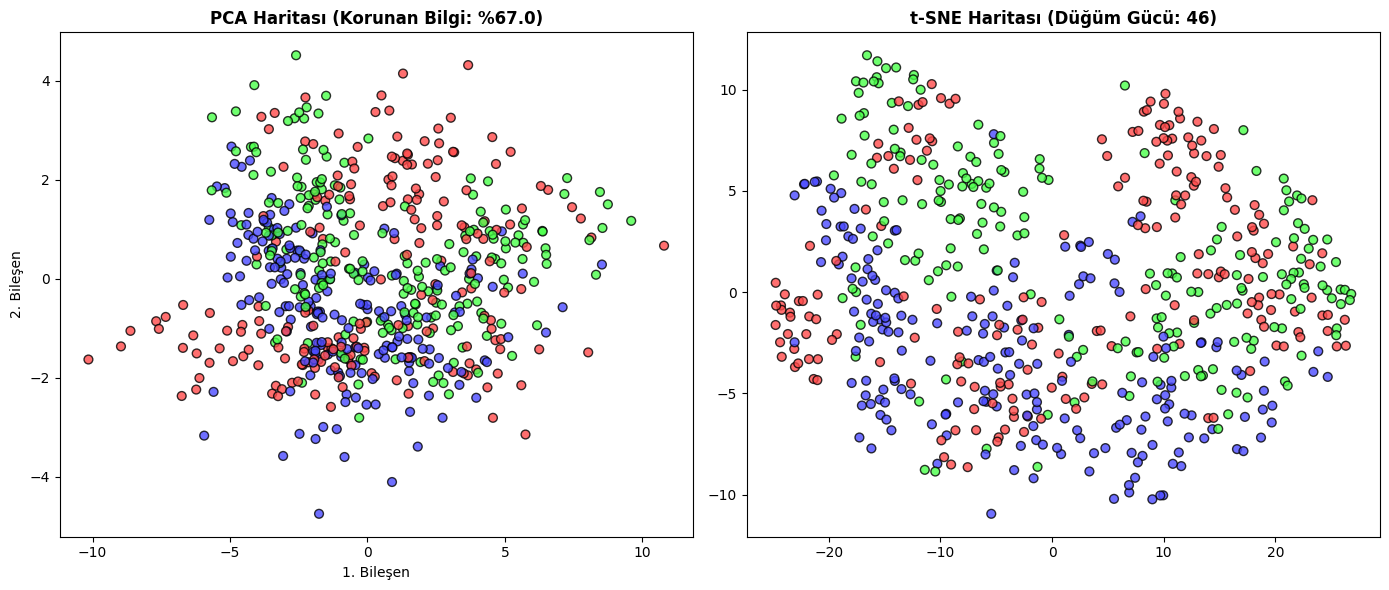

ANALİZ (Zorluk: 0.89): Evren baştan yaratıldı!
Hücreyi tekrar çalıştırdığınızda haritaların tamamen yön ve şekil değiştirdiğini göreceksiniz.


In [71]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from matplotlib.colors import ListedColormap

import warnings
warnings.filterwarnings('ignore')

print("="*75)
print("1. AŞAMA: HER SEFERİNDE DEĞİŞEN 10 BOYUTLU EVREN")
print("="*75)

# KURAL 1: Evrenin kodu ve sınıfların iç içe geçme zorluğu sürekli değişecek!
rastgele_tohum = np.random.randint(1, 10000)
zorluk_derecesi = np.random.uniform(0.5, 2.0) # 0.5 çok karışık, 2.0 çok temiz

# 10 Boyutlu, 3 Sınıflı Dinamik Veri Seti
X_10d, y = make_classification(n_samples=600, n_features=10, n_informative=4, 
                               n_redundant=2, n_classes=3, class_sep=zorluk_derecesi, 
                               random_state=rastgele_tohum)

# PCA ve t-SNE (t-SNE'nin düğüm çözme parametresini de rastgele yaptık)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_10d)

tsne_karmasiklik = np.random.randint(20, 50)
tsne = TSNE(n_components=2, perplexity=tsne_karmasiklik)
X_tsne = tsne.fit_transform(X_10d)

# Haritaları Çizdirme
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
renk_haritasi = ListedColormap(['#FF4B4B', '#4B4BFF', '#4BFF4B'])

# PCA
ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap=renk_haritasi, edgecolors='k', s=40, alpha=0.8)
ax1.set_title(f"PCA Haritası (Korunan Bilgi: %{sum(pca.explained_variance_ratio_)*100:.1f})", fontweight='bold')
ax1.set_xlabel("1. Bileşen"); ax1.set_ylabel("2. Bileşen")

# t-SNE
ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap=renk_haritasi, edgecolors='k', s=40, alpha=0.8)
ax2.set_title(f"t-SNE Haritası (Düğüm Gücü: {tsne_karmasiklik})", fontweight='bold')

plt.tight_layout()
plt.show()

print(f"ANALİZ (Zorluk: {zorluk_derecesi:.2f}): Evren baştan yaratıldı!")
print("Hücreyi tekrar çalıştırdığınızda haritaların tamamen yön ve şekil değiştirdiğini göreceksiniz.")


⚔️ 2. AŞAMA: ALGORİTMALARIN DİNAMİK ÇARPIŞMASI


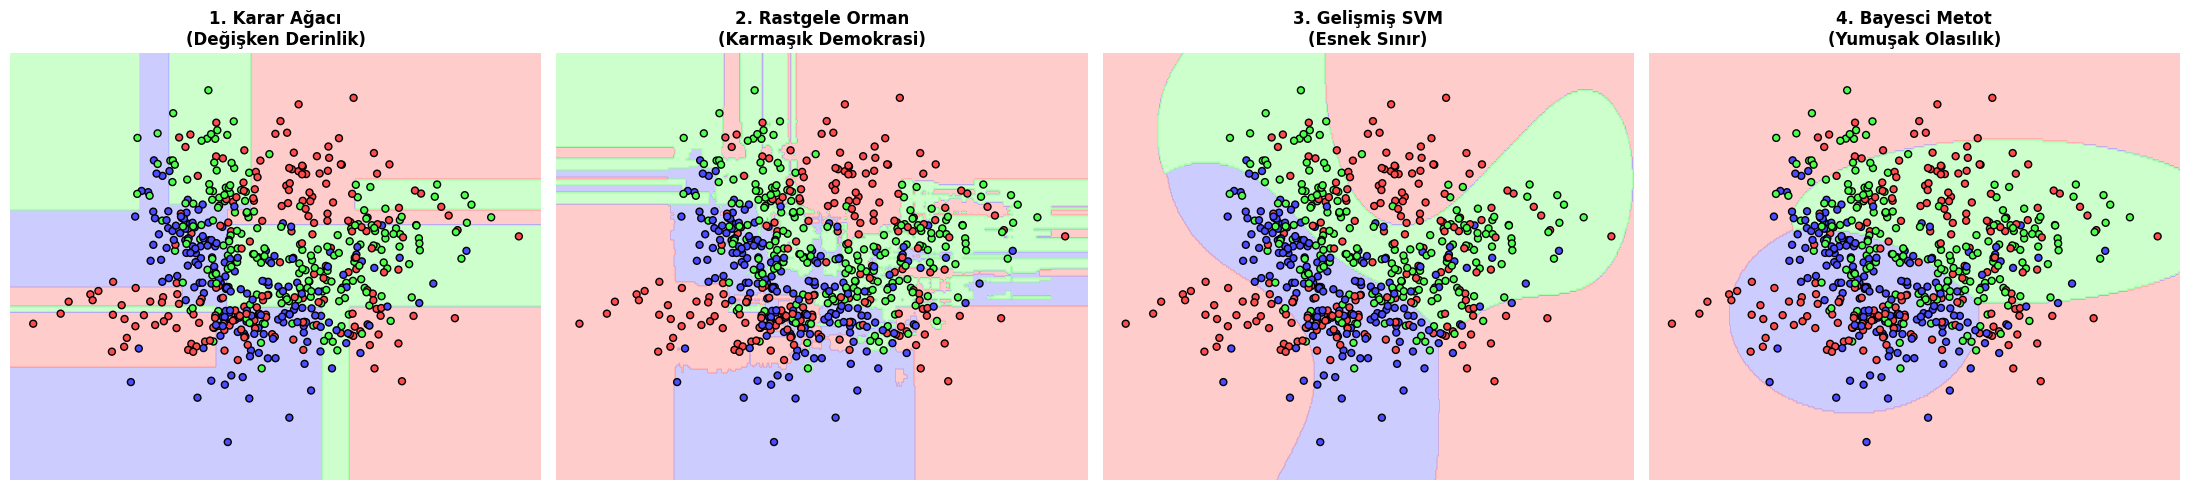

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

print("\n" + "="*75)
print("2. AŞAMA: ALGORİTMALARIN DİNAMİK ÇARPIŞMASI")
print("="*75)

# Tüm modellerden random_state kilitleri söküldü!
modeller = {
    "1. Karar Ağacı\n(Değişken Derinlik)": DecisionTreeClassifier(max_depth=np.random.randint(3, 8)),
    "2. Rastgele Orman\n(Karmaşık Demokrasi)": RandomForestClassifier(n_estimators=50),
    "3. Gelişmiş SVM\n(Esnek Sınır)": SVC(kernel='rbf', C=1.0, gamma='scale'),
    "4. Bayesci Metot\n(Yumuşak Olasılık)": GaussianNB()
}

h = 0.05
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, eksenler = plt.subplots(1, 4, figsize=(22, 5))

for i, (isim, model) in enumerate(modeller.items()):
    ax = eksenler[i]
    model.fit(X_pca, y)
    
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=ListedColormap(['#FFAAAA', '#AAAAFF', '#AAFFAA']), alpha=0.6)
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap=renk_haritasi, edgecolors='k', s=25)
    
    ax.set_title(isim, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()